In [1]:
from IPython.display import Image
from Structure_information import DHN
import random

In [2]:
DHN_1=DHN("Directed",layout="spring")
DHN_1.Graph_From_Excel("C:\\Users\\sserranose\\OneDrive - INSA Lyon\\Bureau\\Code\\Panda_pipes\\Simulation_Bases\\Main_1\\I_2.xlsx")
DHN_1.create_pandapipes_plus_initialization()
DHN_1.plant_support_charateristics_excel.empty
DHN_1.Creation_objects()
input_variables={"pipe_objects":{'T_amb':[273.15,283.15,284]},
                 "Consumer":[{"Q_building_profile":[45000,35000,65000],"T_return_design": 305}],
                "Slack_Central_production":{"T_out_design":350,"P_out_design":3,"P_lift_design":0.5},
                "HP_actors":[{"mode":["COOLING_NET","COOLING_NET","COOLING_NET"],"T_cons":[[323.15,333.15],[323.15,333.15],[323.15,333.15]],"Q_consumer":[-15000,-15000,-15000],'dT_water': [10,10,10]},{"mode":["HEATING_NET","HEATING_NET","HEATING_NET"],"T_cons":[[308.15,298.15],[308.15,298.15],[308.15,298.15]],"Q_consumer":[-15000,-15000,-15000] ,'dT_water': [-10,-10,-10]}],
                "Storage_actors":[{"mass_flow":[0.85,-0.150,0.150],'T_amb':[273.15,283.15,284]}],
                "multi_plant":[{"T_out_design":[],"Q_nominal":[]}]}
DHN_1.def_input_variables_simulation(consumer_actors=DHN_1.Consumer_actors,slack_plant=DHN_1.slack_plant,
                                   input_variables=input_variables,HP_actors=DHN_1.HP_actors,Storage_actors=DHN_1.Storage_actors,
                                   multi_plant_actors=DHN_1.multi_plant_actors,pipe_objects=DHN_1.Pipe_objects)

T_prev={}
Dynamic_actors=DHN_1.Consumer_actors["Object"]+DHN_1.HP_actors["Object"]+DHN_1.Storage_actors["Object"]
for a in Dynamic_actors:
    T_prev[a.name]=random.uniform(35+273.15,60+273.15)  
DHN_1.simulate_period_time(DHN_1.net,consumer_actors=DHN_1.Consumer_actors,slack_plant=DHN_1.slack_plant,
                                   HP_actors=DHN_1.HP_actors,Storage_actors=DHN_1.Storage_actors,
                                   multi_plant_actors=DHN_1.multi_plant_actors,
                                   pipe_objects=DHN_1.Pipe_objects,
                                   T_prev=T_prev,print_iteration=False,n_hours=3,
                                   tol_k=1E-6,max_iter=1000,relax=1)
DHN_1.generate_report(input_variables, Detailed_report=True,generate_data=True,write_detailed_report_name="simulation_report.txt",data_report_name="simulation_data_report.xlsx")

im here 

 iter  | residual   | progress   | massflow   | pressure   | enthalpy   | fluid      | energy     | component  
-------+------------+------------+------------+------------+------------+------------+------------+------------
 1     | 8.64e+05   | 0 %        | 1.74e+00   | 1.38e+06   | 3.98e+05   | 0.00e+00   | 0.00e+00   | 0.00e+00   
 2     | 7.42e+04   | 12 %       | 1.44e+00   | 1.73e+05   | 6.59e+03   | 0.00e+00   | 0.00e+00   | 0.00e+00   
 3     | 6.76e+03   | 24 %       | 1.62e-01   | 1.28e+04   | 3.45e+02   | 0.00e+00   | 0.00e+00   | 0.00e+00   
 4     | 1.04e+00   | 66 %       | 4.01e-06   | 9.24e+01   | 2.47e+00   | 0.00e+00   | 0.00e+00   | 0.00e+00   
 5     | 6.96e-05   | 100 %      | 1.52e-10   | 4.70e-03   | 1.07e-04   | 0.00e+00   | 0.00e+00   | 0.00e+00   
 6     | 5.25e-10   | 100 %      | 2.59e-13   | 2.29e-07   | 3.38e-08   | 0.00e+00   | 0.00e+00   | 0.00e+00   
Total iterations: 6, Calculation time: 0.03 s, Iterations per second: 221.61

 iter  | residua

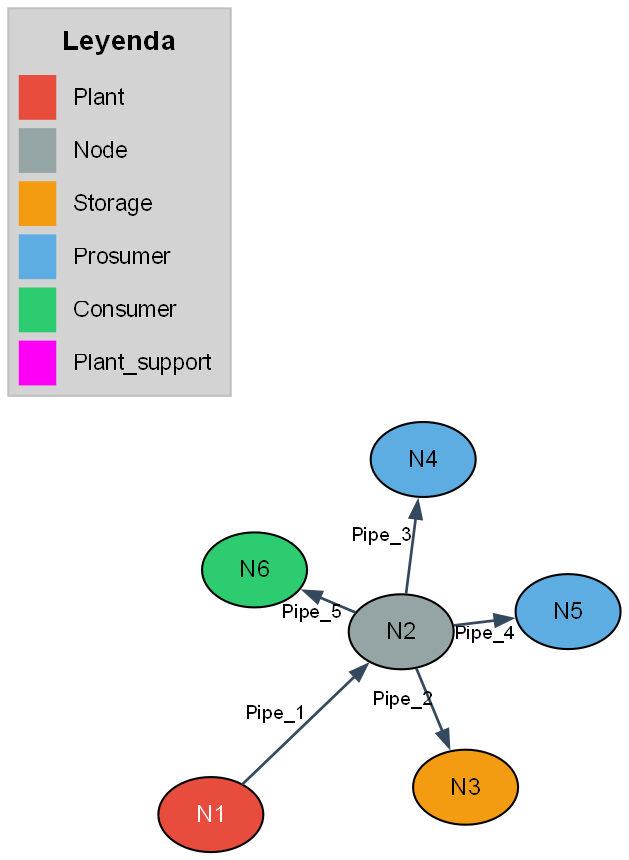

In [3]:
Image("network.png") 